# Interpolation

### 


Import von Bibliotheken:

In [10]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

### Lineare Interpolation (1D)

Hier wird ein Datensatz mit $n=20$ Punkten aus der Sinusfunktion $y = \text{sin}(x)$ generiert.

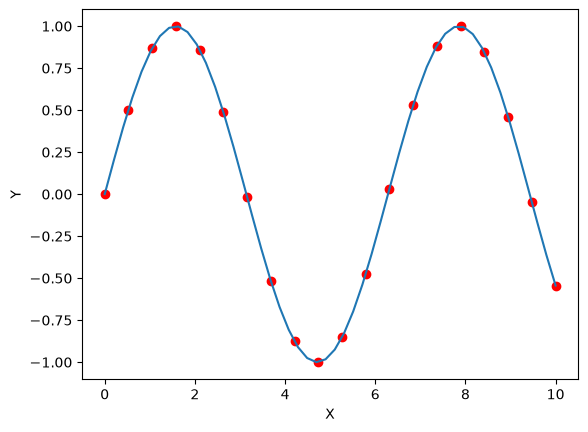

In [11]:
n = 20
x = np.linspace(0,10,n)
y = np.sin(x)

plt.scatter(x,y,color='r')
plt.xlabel('X')
plt.ylabel('Y')

# Durchgehende Sinuskurve
plt.plot(np.linspace(0,10),np.sin(np.linspace(0,10)))

Der Wert $y$ des interpolierten Punkt an der Stelle $x$ errechnet sich durch

$y = \frac{(x_1 - x)\cdot y_0\ +\ (x - x_0)\cdot y_1}{x_1-x_0},$

wobei $(x,y)$ zwischen den Punkten $(x_0, y_0)$ und $(x_1, y_1)$ liegt. Die Normierung $\frac{1}{x_1-x_0}$ ist hingegen bei Bildern nicht notwendig, da der Abstand zwischen zwei Pixeln immer 1 ist.

Ergänzen Sie die Funktion `interpolate1d()`, welche den einzelnen $y$-Wert `y_interpolated` an der Stelle `x_interpolated` zurückgibt.
Des Weiteren bekommt die Funktion alle Punkte `x` und `y`, sowie den Index `idx` des nächstkleineren Punktes $(x_0, y_0)$.

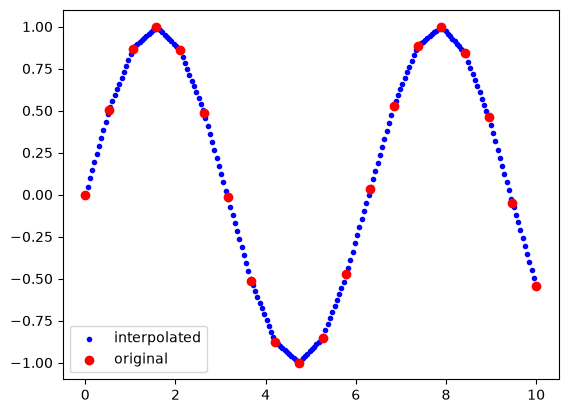

In [13]:
def interpolate1d(x_interpolated,idx,x,y):
    # Code hier
    y_interpolated = y[idx] + (y[idx+1]-y[idx])/(x[idx+1]-x[idx])*(x_interpolated-x[idx])
    return  y_interpolated


n_interpolated = 200 #Größe des neuen Datensatzes
x_interpolated = np.linspace(0,10,n_interpolated)

# Interpolation aller Punkte
y_interpolated = np.zeros(n_interpolated)
scale = (n-1)/(n_interpolated-1) #Skalierung der Koordinaten
for i in range(n_interpolated-1):
    idx = int(i*scale) #Index des vorherigen Punkts - int schneidet Stellen nach dem Komma ab
    
    y_interpolated[i] = interpolate1d(x_interpolated[i], idx, x, y)

y_interpolated[-1] = y[-1] #Sonderfall bei letztem Punkt

# Darstellung der interpolierten Punkte
#plt.plot(x_interpolated, y_interpolated)
plt.scatter(x_interpolated, y_interpolated, color='b', marker='.', label='interpolated')
plt.scatter(x,y,color='r', label='original')
plt.legend()

Aktuell ist `n`<`n_interpolated`, sodass sich die Abtastrate erhöht. Ändern Sie die Werte von `n` und `n_interpolated`, sodass `n_interpolated`<`n` (Downsampling).

### Bilineare Interpolation (2D)

Hier soll die Größe eines Bildes geändert werden.

Bild: [Lunch atop a Skyscraper](https://en.wikipedia.org/wiki/Lunch_atop_a_Skyscraper), 1932, RCA Building, New York

Import von Bild:

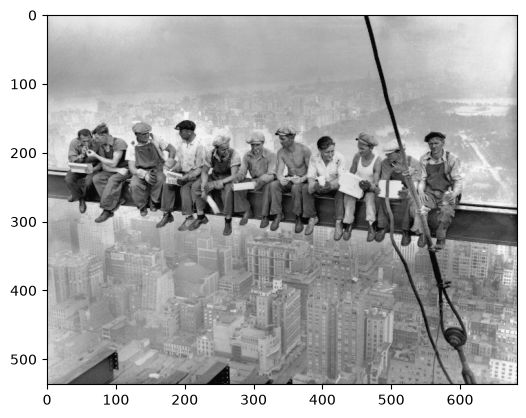

In [14]:
img = cv2.imread("Lunch_atop_a_Skyscraper.png", 0) #Argument 0 sorgt für lesen als Graustufenbild

plt.imshow(img, cmap="gray")
plt.show()

# Zahl der Grauwerte
L = 256

Bei der Bilinearen Interpolation wird der Grauwert $f$ an der Stelle $(x,y)$ mithilfe der vier umliegenden Pixelwerte errechnet:

$\begin{aligned}f(x,y) =& (i+1 - x)(j+1 - y) f(i,j)\\
&+ (x - i)(j+1 - y) f(i+1,j) \\
&+ (i+1 - x)(y - j) f(i,j+1) \\
&+ (x - i)(y - j) f(i+1,j+1)
\end{aligned}$

Schreiben Sie die Funktion `interpolate2d()`, welche die Berechnung durchführt. Eine Normierung wird hier nicht benötigt.

In [15]:
def interpolate2d(i, j, x, y, img):
    interpolated_value = (
        (i + 1 - x) * (j + 1 - y) * img[i,     j] +
        (x - i)     * (j + 1 - y) * img[i + 1, j] +
        (i + 1 - x) * (y - j)     * img[i,     j + 1] +
        (x - i)     * (y - j)     * img[i + 1, j + 1]
    )
    return interpolated_value

Wenden Sie die Funktion an, um die Größe des Bildes zu verändern.

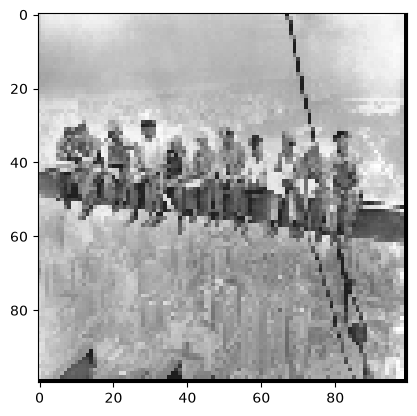

In [16]:
m_resampled, n_resampled = 100, 100 #neue Bildgröße
m, n = img.shape

img_resampled = np.zeros((m_resampled, n_resampled))
m_scale = (m - 1)/(m_resampled - 1)
n_scale = (n - 1)/(n_resampled - 1)

for k in range(m_resampled):
    for l in range(n_resampled):
        # Pixelkoordinaten im Originalbild
        x = k * m_scale
        y = l * n_scale

        # Sonderfälle für Randbereiche
        if int(x) == m-1 and int(y) == n-1:
            img_resampled[k,l] = 0 #Hier Pixel für Randbereiche ergänzen
            break
        elif int(x) == m-1:
            img_resampled[k,l] = 0 #Hier Pixel für Randbereiche ergänzen
            continue
        elif int(y) == n-1:
            img_resampled[k,l] = 0 #Hier Pixel für Randbereiche ergänzen
            continue


        # Interpolierte Pixel
        img_resampled[k,l] = interpolate2d(int(x), int(y), x, y, img)

plt.imshow(img_resampled, cmap="gray")
plt.show()

Interpolieren Sie nun ein Farbbild.

Bild: [Martinswand Vorbau](https://www.climbers-paradise.com/mehrseillaengen-innsbruck-tirol/location/martinswand-mehrseillaengen/), 01.11.2023

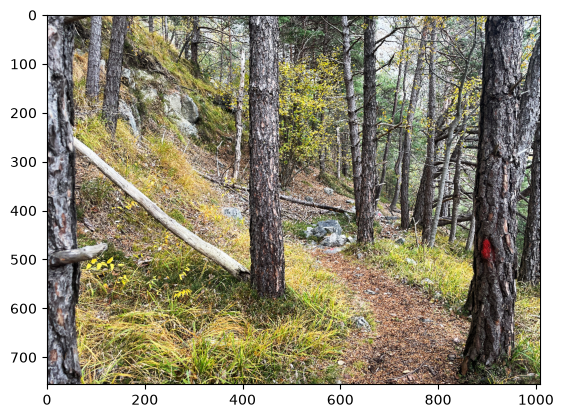

In [17]:
img = cv2.imread("martinswand_vorbau.png")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB) # OpenCV importiert als BGR. Konvertierung zu RGB für späteres Anzeigen
plt.imshow(img)
plt.show()

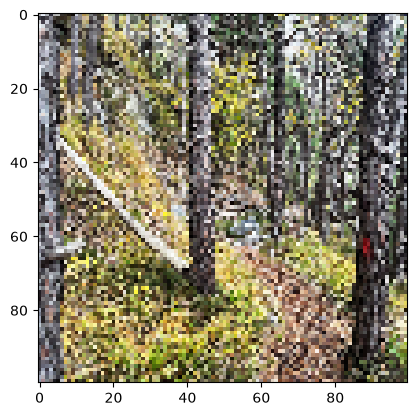

In [21]:
m_resampled, n_resampled = 100, 100 #neue Bildgröße

# Code hier
def interpolate2d(i, j, x, y, img):
    i1 = min(i + 1, img.shape[0] - 1)
    j1 = min(j + 1, img.shape[1] - 1)

    dx = x - i
    dy = y - j

    return (
        (1 - dx) * (1 - dy) * img[i,  j] +
        dx       * (1 - dy) * img[i1, j] +
        (1 - dx) * dy       * img[i,  j1] +
        dx       * dy       * img[i1, j1]
    )
m, n, channels = img.shape

img_resampled = np.zeros(
    (m_resampled, n_resampled, channels),
    dtype=np.float32
)

m_scale = (m - 1) / (m_resampled - 1)
n_scale = (n - 1) / (n_resampled - 1)

for k in range(m_resampled):
    for l in range(n_resampled):
        x = k * m_scale
        y = l * n_scale
        i, j = int(x), int(y)

        img_resampled[k, l] = interpolate2d(i, j, x, y, img)

plt.imshow(img_resampled.astype(int))
plt.show()

### Aliasing

Foto: Jeans Nahaufnahme

Aliasing tritt bei Bildern auf, wenn die Strukturen einer bestimmten Frequenz entsprechen, die die Nyquist-Frequenz überschreitet. Im folgenden ist eine Nahaufnahme einer Jeans gegeben.

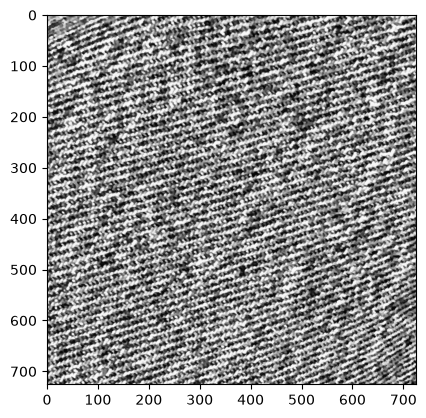

(726, 726)


In [22]:
img = cv2.imread("jeans.png",0) #Argument 0 sorgt für Einlesen als Graustufenbild

plt.imshow(img, cmap="gray")
plt.show()
print(img.shape)

Bei einer entsprechenden Umformung sieht man, dass die ursprünglich fast waagrechten Strukturen sich jetzt annähernd senkrecht durch das Bild ziehen.

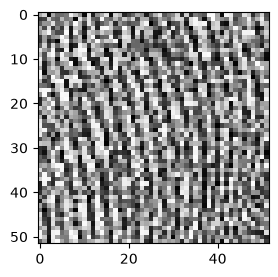

In [23]:
size = 52,52
plt.figure(figsize=(3,3))
img_alias = cv2.resize(img, size)
plt.imshow(img_alias, cmap="gray")
plt.show()

### OpenCV

OpenCV hat die Funktion [`cv2.resize()`](https://docs.opencv.org/4.x/da/d54/group__imgproc__transform.html#ga47a974309e9102f5f08231edc7e7529d) implementiert, um die Größe des Bildes zu verändern. Beispielsweise wurde das Bild hier quadratisch auf 100x100 Pixel umgeformt.

Durch ersetzen des Arguments `interpolation` lassen sich auch andere Methoden anwenden, z.B.\
`INTER_LINEAR`: Bilineare Interpolation mithilfe der 2x2 umgebenden Pixel\
`INTER_CUBIC`: Bikubische Interpolation mithilfe kubischer Polynome anhand der umgebenden 4x4 Pixel\
`INTER_NEAREST`: Nearest Neighbours - die neuen Pixel nehmen den Wert des nächstgelegenen Pixels an.

Testen Sie verschiedene Interpolationsmethoden und deren Unterschiede. Versuchen Sie das Bild sowohl Up- als auch Downzusamplen.

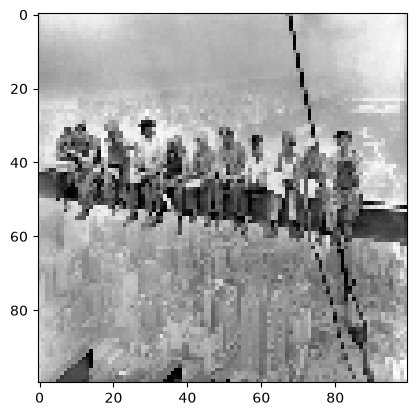

In [24]:
size = (100, 100) #neue Größe
img = cv2.imread("Lunch_atop_a_Skyscraper.png", 0)

img_resized = cv2.resize(img, size, interpolation=cv2.INTER_LINEAR)

plt.imshow(img_resized, cmap="gray")
plt.show()

Mit [`cv2.imwrite()`](https://docs.opencv.org/4.x/d4/da8/group__imgcodecs.html#ga8ac397bd09e48851665edbe12aa28f25) lässt sich das neue Bild abspeichern.

In [25]:
cv2.imwrite('lunch_newsize.png', img_resized) 

True